# 06 · ₹ impact: what the exceptions are worth, and what to fix first

Days 1–5 built, validated and published the reconciliation. A controller still has to decide **where the team's time goes**, and that needs rupees. This notebook sizes the October exceptions three ways, because they answer different questions:

| Section | Question | Nature |
|---|---|---|
| **A · Cash to recover now** | What can we claim back this close? | one-off |
| **B · Books wrong if closed now** | How far off would October revenue be without the engine, and is it material? | accuracy |
| **C · Recurring cost per year** | What keeps leaking every month until the cause is fixed? | run rate |

The model is SQL (`impact/impact.sql`) on top of the engine tables; `src/impact.py` runs it. It reads no truth labels. Two assumptions are parameters, not hard-coded: **cost of funds 10% a year** and **performance materiality 0.5% of revenue** (a common audit rule of thumb). Then the same model runs on the 20 regenerated months from Day 4 to put a range on the annual figures.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import impact
from match import build

pd.set_option("display.width", 180); pd.set_option("display.max_colwidth", 70)
IMG, OUT = ROOT / "images", ROOT / "data" / "output"
INK, MUTED, ACCENT, WARN, OK, AMBER = "#1f2937", "#9ca3af", "#2563eb", "#dc2626", "#16a34a", "#f59e0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
inr = lambda v: f"₹{v:,.2f}"
lakh = lambda v: f"₹{v/1e5:,.2f} L"

res = impact.size(ROOT / "data" / "clean")
lines, s, fee = res["impact_lines"], res["impact_summary"].iloc[0], res["fee_run_rate"]
lines[["section", "line", "owner", "month_inr", "annual_inr", "basis"]].round(2)

,section,line,owner,month_inr,annual_inr,basis
0,A,Held settlement (19 Oct batch),Treasury,641741.68,NaN,one-off
1,A,Fee overcharge refund claim,Treasury / vendor manager,3953.16,NaN,one-off
2,A,Chargebacks to contest (upper bound),Finance (AR),25150.00,NaN,"one-off, upper bound"
3,B,Receipts with no captured payment (no record + failed),Finance (AR),161250.00,NaN,overstated
4,B,"Refunds paid out, no credit note",Finance (AR),92726.50,NaN,overstated
5,B,"Chargebacks netted, not booked",Finance (AR),25150.00,NaN,overstated
6,B,Checkout discounts not in the ERP,E-commerce ops,11553.00,NaN,overstated
7,B,Captured payments never booked,Finance (GL),-61929.00,NaN,understated
8,C,Fee overcharge at current rates: Card,Treasury / vendor manager,508.01,5981.41,run rate x 365 days
9,C,Fee overcharge at current rates: Wallet,Treasury / vendor manager,6396.83,75317.50,run rate x 365 days


## 1 · A: cash to recover now

In [2]:
a = lines[lines.section == "A"]
display(a[["line", "owner", "action", "month_inr"]].round(2))
print(f"cash to recover this close: {inr(s.cash_to_recover)} ({lakh(s.cash_to_recover)})")
print(f"held settlement share of it: {a.month_inr.iloc[0] / s.cash_to_recover:.1%}")

,line,owner,action,month_inr
0,Held settlement (19 Oct batch),Treasury,Escalate to PayFlux; book a receivable from the gateway,641741.68
1,Fee overcharge refund claim,Treasury / vendor manager,Claim the October excess with the fee_audit extract,3953.16
2,Chargebacks to contest (upper bound),Finance (AR),Contest with delivery proof inside the gateway window,25150.00


cash to recover this close: ₹670,844.84 (₹6.71 L)
held settlement share of it: 95.7%


The held payout dominates. It is not lost money (the gateway owes it), but until it is booked as a receivable from PayFlux the October cash position is understated, and nobody chases it. The fee claim is small in rupees; its value is in section C.

## 2 · B: how wrong October revenue would be, and is it material?

In [3]:
b = lines[lines.section == "B"]
display(b[["line", "owner", "month_inr", "basis"]].round(2))
print(f"ERP net sales:              {inr(s.erp_net_sales)}")
print(f"net revenue overstatement:  {inr(s.net_revenue_overstatement)} ({s.overstatement_share:.3%} of net sales)")
print(f"gross misstatement (|+|+|-|): {inr(s.gross_revenue_misstatement)}")
print(f"materiality threshold (0.5%): {inr(s.materiality_threshold)} -> material: {bool(s.is_material)}")
print(f"overstatement is {s.net_revenue_overstatement / s.materiality_threshold:.2f}x the threshold; "
      f"it stays material for any threshold below {s.overstatement_share:.3%}")

,line,owner,month_inr,basis
3,Receipts with no captured payment (no record + failed),Finance (AR),161250.0,overstated
4,"Refunds paid out, no credit note",Finance (AR),92726.5,overstated
5,"Chargebacks netted, not booked",Finance (AR),25150.0,overstated
6,Checkout discounts not in the ERP,E-commerce ops,11553.0,overstated
7,Captured payments never booked,Finance (GL),-61929.0,understated


ERP net sales:              ₹21,991,231.50
net revenue overstatement:  ₹228,750.50 (1.040% of net sales)
gross misstatement (|+|+|-|): ₹352,608.50
materiality threshold (0.5%): ₹109,956.16 -> material: True
overstatement is 2.08x the threshold; it stays material for any threshold below 1.040%


Without the engine, October would close with revenue overstated by about 1% of sales, roughly twice a typical performance-materiality threshold. Every item in it is small; the problem is that there are 400+ of them and they all point the same way (bookings without cash, refunds and chargebacks without credit notes).

### Does that hold in other months?

In [4]:
m = pd.read_csv(OUT / "impact_months.csv")
print(f"{len(m)} regenerated months: overstatement {m.overstatement_share.min():.3%} – {m.overstatement_share.max():.3%} "
      f"of net sales (mean {m.overstatement_share.mean():.3%}); material in {int(m.is_material.sum())} of {len(m)}")
m[["seed", "erp_net_sales", "net_revenue_overstatement", "overstatement_share", "cash_to_recover", "fee_leakage_annual"]].round(4).head()

20 regenerated months: overstatement 0.851% – 1.214% of net sales (mean 1.059%); material in 20 of 20


,seed,erp_net_sales,net_revenue_overstatement,overstatement_share,cash_to_recover,fee_leakage_annual
0,101,22053889.0,225200.0,0.0102,716661.81,83281.8157
1,102,22020265.5,234745.0,0.0107,691680.58,77121.4180
2,103,21814219.5,226013.0,0.0104,750309.72,83460.8551
3,104,21970817.0,260318.5,0.0118,747526.91,82844.0667
4,105,21973219.0,229540.0,0.0104,701850.13,78701.5834


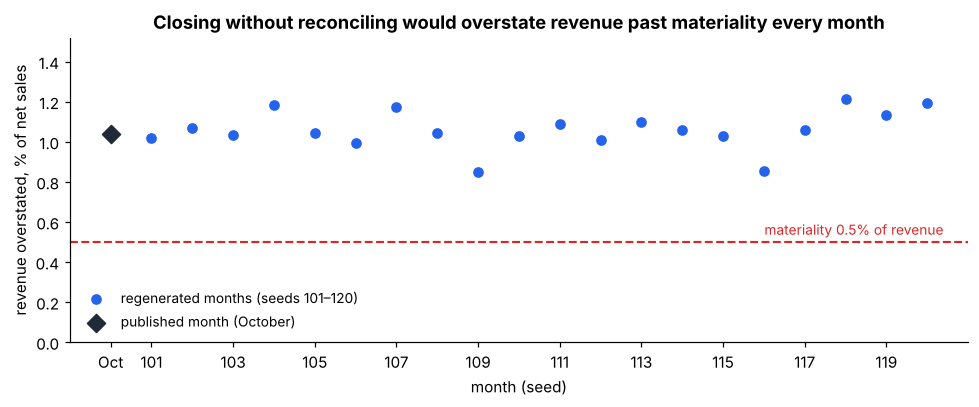

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(m.seed, m.overstatement_share * 100, color=ACCENT, s=36, label="regenerated months (seeds 101–120)", zorder=3)
ax.scatter([100], [s.overstatement_share * 100], color=INK, s=70, marker="D", label="published month (October)", zorder=3)
ax.axhline(0.5, color=WARN, ls="--", lw=1.4)
ax.text(120.4, 0.52, "materiality 0.5% of revenue", color=WARN, ha="right", va="bottom", fontsize=9)
ax.set_ylim(0, max(m.overstatement_share.max(), s.overstatement_share) * 100 * 1.25)
ax.set_xticks([100] + list(m.seed[::2])); ax.set_xticklabels(["Oct"] + [str(x) for x in m.seed[::2]])
ax.set_ylabel("revenue overstated, % of net sales"); ax.set_xlabel("month (seed)")
ax.set_title("Closing without reconciling would overstate revenue past materiality every month")
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.tight_layout(); fig.savefig(IMG / "16_misstatement_vs_materiality.png", dpi=150); plt.show()

## 3 · C: what keeps costing money every year

**Fee leakage at the current rate.** Using the whole month would understate the wallet problem, because the overcharge only started on 15 Oct. `fee_run_rate` uses the `LAG()`-detected step date (`fee_rate_changes`, from `sql/30_fee_audit.sql`) and prices only the days since: that is the rate PayFlux will keep charging. Card overcharges have no step, so the whole month is the run rate. Annual = excess per ₹ at the current rate × average daily volume × 365.

In [6]:
display(fee[["method", "regime_start", "regime_volume", "regime_excess", "excess_per_rupee", "avg_daily_volume", "annual_leakage"]].assign(regime_start=lambda d: d.regime_start.astype(str)).round(6))
print(f"October fee claim (what was actually overcharged): {inr(lines.loc[lines.line == 'Fee overcharge refund claim', 'month_inr'].iloc[0])}")
print(f"annual leakage at current rates:                  {inr(s.fee_leakage_annual)}")
w = fee.set_index("method")
print(f"wallet: {w.loc['Wallet', 'annual_leakage'] / s.fee_leakage_annual:.1%} of the annual figure")

,method,regime_start,regime_volume,regime_excess,excess_per_rupee,avg_daily_volume,annual_leakage
0,Card,2026-10-01,5577309.0,508.01,0.000091,179913.193548,5981.408065
1,Wallet,2026-10-15,1167838.0,3445.15,0.002950,69948.354839,75317.501019


October fee claim (what was actually overcharged): ₹3,953.16
annual leakage at current rates:                  ₹81,298.91
wallet: 92.6% of the annual figure


The October claim is ₹3,953 because the wallet step landed mid-month. At the new rate, the same overcharge is worth about ₹81k a year, roughly 20× the claim. That is why this goes to the vendor manager now, not as a small item at year end.

In [7]:
a_rng = pd.read_csv(OUT / "impact_annual_range.csv")
display(a_rng.round(0))
c = lines[lines.section == "C"]
print(f"cost of funds on the held payout (per occurrence): {inr(c.loc[c.line.str.startswith('Cost of funds'), 'month_inr'].iloc[0])}")

,line,annual_mean_inr,ci95_lo_inr,ci95_hi_inr,min_month_x12_inr,max_month_x12_inr,months
0,Fee overcharge at current rates,82307.0,81465.0,83129.0,77121.0,86894.0,20
1,Receipts with no captured payment,1885455.0,1808371.0,1959915.0,1579116.0,2142492.0,20
2,Chargebacks,342860.0,325601.0,360788.0,286404.0,438780.0,20
3,Revenue overstated if closed unreconciled,2785790.0,2674129.0,2889182.0,2235414.0,3207318.0,20


cost of funds on the held payout (per occurrence): ₹1,934.02


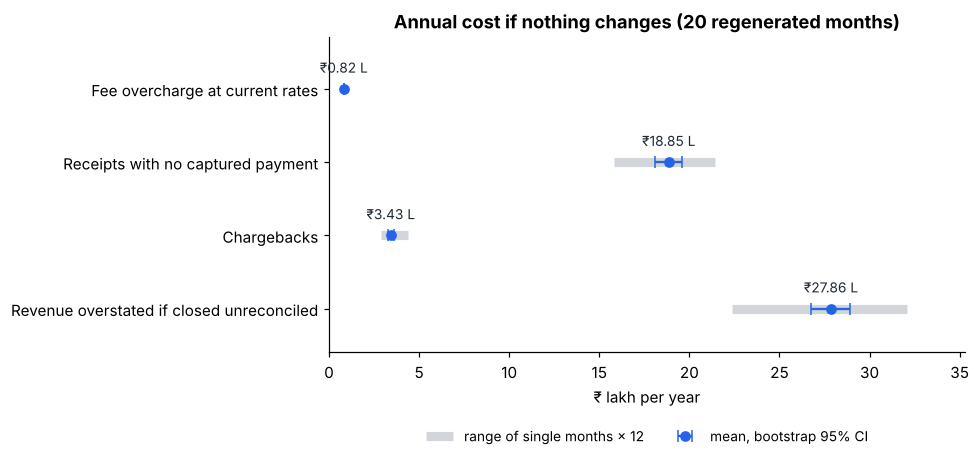

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.4))
r = a_rng.iloc[::-1].reset_index(drop=True)
y = np.arange(len(r))
ax.hlines(y, r.min_month_x12_inr / 1e5, r.max_month_x12_inr / 1e5, color=MUTED, lw=6, alpha=.45, label="range of single months × 12")
ax.errorbar(r.annual_mean_inr / 1e5, y, xerr=[(r.annual_mean_inr - r.ci95_lo_inr) / 1e5, (r.ci95_hi_inr - r.annual_mean_inr) / 1e5],
            fmt="o", color=ACCENT, capsize=4, label="mean, bootstrap 95% CI")
for yi, v in zip(y, r.annual_mean_inr):
    ax.text(v / 1e5, yi + .22, lakh(v), ha="center", fontsize=9, color=INK)
ax.set_yticks(y); ax.set_yticklabels(r.line)
ax.set_xlabel("₹ lakh per year"); ax.set_xlim(0, r.max_month_x12_inr.max() / 1e5 * 1.1)
ax.set_title("Annual cost if nothing changes (20 regenerated months)")
ax.set_ylim(-0.6, len(r) - 0.3)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=9)
fig.tight_layout(); fig.savefig(IMG / "17_annual_range.png", dpi=150); plt.show()

**How to read the range.** The 20 months share the same injection rates, so the interval measures month-to-month noise in orders and amounts, not uncertainty about the rates themselves. It says the annual figure is stable; it does not say the rates won't change. The "receipts with no captured payment" line is *revenue at risk*: it becomes a loss only for orders that shipped without payment, which the ERP extract can't tell us. The held payout isn't annualised, because one held batch a month is the generator's assumption, not something October proves.

## 4 · Speed: what monthly reconciliation costs in time

Day 5 showed that 46.8% of breaks were more than 14 days old at close. In ₹ terms, the useful measure is **break-days**: the value of each break times the days it sat unseen. Run daily, the same engine would show each break the morning after it happens.

485 breaks, median age at close 14 days; 227 older than 14 days worth ₹159,839.50
₹ break-days unseen, monthly close: 12,013,244; daily run (seen next day): 994,350 -> 91.7% less exposure


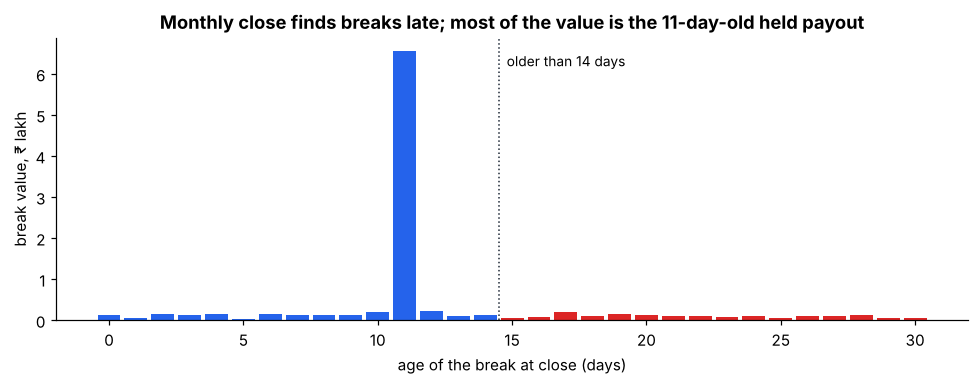

In [9]:
con = build()
reg = con.sql("SELECT * FROM exception_register WHERE class = 'break'").df()
reg["abs_inr"] = reg.impact_inr.abs()
monthly = (reg.abs_inr * reg.age_days.clip(lower=0)).sum()
daily = (reg.abs_inr * 1).sum()
print(f"{len(reg)} breaks, median age at close {reg.age_days.median():.0f} days; "
      f"{int((reg.age_days > 14).sum())} older than 14 days worth {inr(reg.loc[reg.age_days > 14, 'abs_inr'].sum())}")
print(f"₹ break-days unseen, monthly close: {monthly:,.0f}; daily run (seen next day): {daily:,.0f} "
      f"-> {1 - daily / monthly:.1%} less exposure")

ages = reg.sort_values("age_days")
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(-0.5, ages.age_days.max() + 1.5, 1)
val = np.histogram(ages.age_days, bins=bins, weights=ages.abs_inr)[0]
ax.bar(bins[:-1] + .5, val / 1e5, width=.85, color=[WARN if b + .5 > 14 else ACCENT for b in bins[:-1]])
ax.axvline(14.5, color=INK, lw=1, ls=":")
ax.text(14.8, ax.get_ylim()[1] * .9, "older than 14 days", fontsize=9)
ax.set_xlabel("age of the break at close (days)"); ax.set_ylabel("break value, ₹ lakh")
ax.set_title("Monthly close finds breaks late; most of the value is the 11-day-old held payout")
fig.tight_layout(); fig.savefig(IMG / "18_break_age.png", dpi=150); plt.show()

## 5 · One picture for the controller

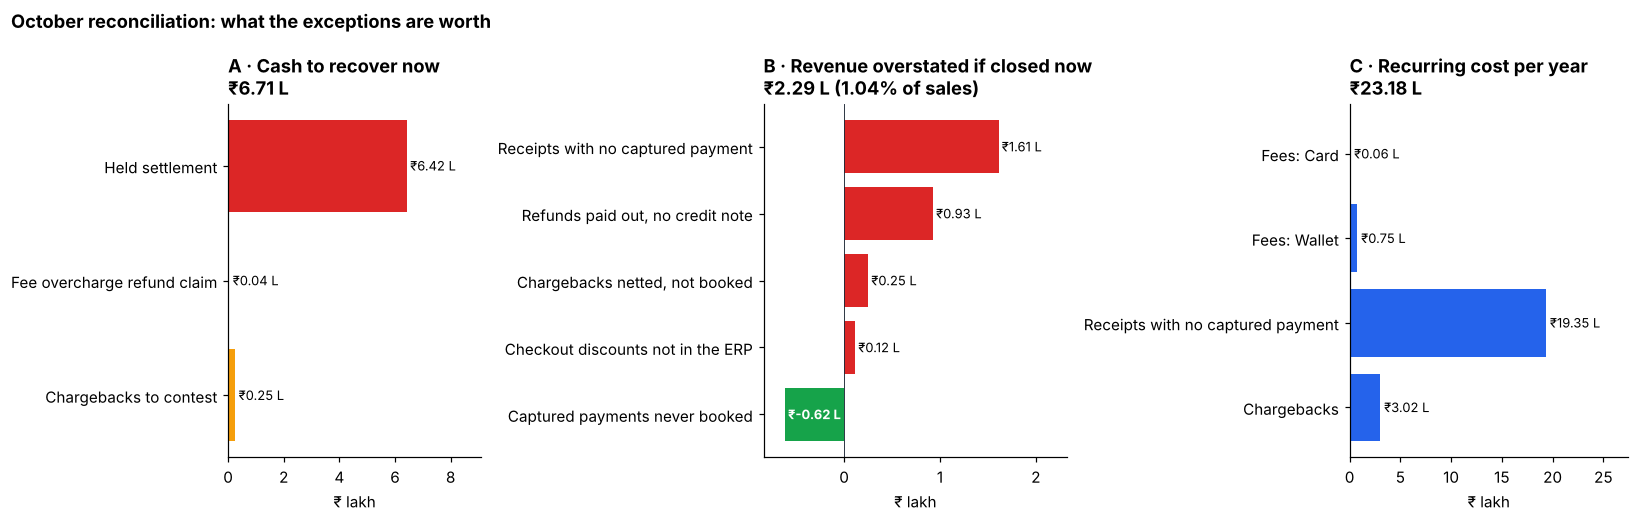

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.2, 1.1]})
def bars(ax, df, col, title, colors, scale=1e5, unit="₹ lakh"):
    df = df.iloc[::-1]
    ax.barh(df.line.str.replace(r" \(.*\)", "", regex=True).str.replace("Fee overcharge at current rates: ", "Fees: "),
            df[col] / scale, color=colors[::-1])
    for i, v in enumerate(df[col]):
        if v >= 0:
            ax.text(v / scale + 0.02 * abs(df[col]).max() / scale, i, lakh(v), va="center", ha="left", fontsize=8.5)
        else:  # label inside a negative bar so it doesn't collide with the category name
            ax.text(v / scale / 2, i, lakh(v), va="center", ha="center", fontsize=8.5, color="white", fontweight="bold")
    ax.set_title(title, loc="left"); ax.set_xlabel(unit); ax.axvline(0, color=INK, lw=.6)
A = lines[lines.section == "A"]; B = lines[lines.section == "B"]
C = lines[(lines.section == "C") & lines.annual_inr.notna()]
bars(axes[0], A, "month_inr", f"A · Cash to recover now\n{lakh(s.cash_to_recover)}", [WARN, AMBER, AMBER])
bars(axes[1], B, "month_inr", f"B · Revenue overstated if closed now\n{lakh(s.net_revenue_overstatement)} ({s.overstatement_share:.2%} of sales)",
     [WARN if v > 0 else OK for v in B.month_inr])
bars(axes[2], C, "annual_inr", f"C · Recurring cost per year\n{lakh(C.annual_inr.sum())}", [ACCENT] * len(C))
for ax in axes: ax.set_xlim(left=min(0, ax.get_xlim()[0] * 1.15), right=ax.get_xlim()[1] * 1.35)
fig.suptitle("October reconciliation: what the exceptions are worth", fontweight="bold", x=.01, ha="left")
fig.tight_layout(); fig.savefig(IMG / "15_impact_overview.png", dpi=150); plt.show()

## 6 · What to do, in order

The full recommendations, with owners and evidence, are in [`reports/recommendations.md`](../reports/recommendations.md). The ranking logic: **cash first** (it's owed now), **then the fix that stops a recurring loss**, **then the process changes that stop the books being wrong** next month.

In [11]:
rec = lines.copy()
rec["priority_inr"] = rec.annual_inr.fillna(rec.month_inr).abs()
rec[rec.section != "B"].sort_values("priority_inr", ascending=False)[["section", "line", "owner", "action", "priority_inr"]].round(2)

,section,line,owner,action,priority_inr
10,C,Receipts with no captured payment,Finance (AR) + E-commerce ops,Block order confirmation until the gateway confirms capture,1935000.00
0,A,Held settlement (19 Oct batch),Treasury,Escalate to PayFlux; book a receivable from the gateway,641741.68
11,C,Chargebacks,Finance (AR),Track chargeback rate by method; contest with evidence,301800.00
9,C,Fee overcharge at current rates: Wallet,Treasury / vendor manager,Get the contract rate reinstated; add the fee audit to every close,75317.50
2,A,Chargebacks to contest (upper bound),Finance (AR),Contest with delivery proof inside the gateway window,25150.00
8,C,Fee overcharge at current rates: Card,Treasury / vendor manager,Get the contract rate reinstated; add the fee audit to every close,5981.41
1,A,Fee overcharge refund claim,Treasury / vendor manager,Claim the October excess with the fee_audit extract,3953.16
12,C,Cost of funds on a held payout (per occurrence),Treasury,Daily payout-to-bank check; escalate on day 1 overdue,1934.02
